<a href="https://colab.research.google.com/github/erikarosado/ia-y-aprendizaje-automatico/blob/main/Actividad_oil_spill_resuelta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Maestría en Inteligencia Artificial Aplicada**

###**Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Problema de Clasificación con Datos Desbalanceados : Oil-Spill**

* **Nombre:** Erika Rosado Treviño

* **Matrícula:** A00846135

# **Introducción**

* La actividad se basa en los datos conocidos como "oil-spill" (derrame de petróleo).

* En la web puedes encontrar varias referencias a este mismo problema, pero en donde el archivo de datos no es exactamente igual. Por ello y para asegurar que el conjunto de datos con el que estaremos trabajando es el mismo para todos, dicho archivo lo encontrarás en Canvas.

* El archivo con los datos de esta actividad lo encuentras en Canvas con el nombre "oil-spill.csv".

* En la siguiente liga se encuentra el artículo original relacionado a dicha base de datos:

https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf

* De dicho artículo sabemos que los datos incluyen 50 columnas y 937 registros. Las primeras 49 columnas son métricas obtenidas de imágenes satelitales del océano, en algunas de las cuales se tiene petróleo que fue derramado por alguna fuente desconocida. En el artículo se describe a detalle la manera en que se obtuvieron dichas columnas. Para la presente actividad es suficiente con saber que dichos valores numéricos son información valiosa que nos permiten entender lo qu hay en la imagen, en particular, el ayudar a distinguir si hay o no derramamiento de combustible en dicha imagen.

* La última columna llamada "target" puede tomar el valor de 1 (hay derrame en ese pedazo de la imagen) o 0 (no hay derrame en ese pedazo de la imagen).

* Así, por el momento es suficiente con que consideres que cada una de las primeras 49 columnas son variables de tipo numérico continua y la última es de valor binario, en este problema de clasificación.

* En un curso posterior de visión computacional dentro de la maestría podrás estudiar técnicas para extraer dicha información numérica de las imágenes, en caso de que este tema sea de tu interés.

* Para fines de esta actividad usaremos la librería llamada "imbalanced-learn", usada comunmente en problemas de clases desbalanceadas. En particular, usaremos el siguiente método que nos proporciona un reporte con los valores de varias métricas utilizadas comunmente en problemas de clases desbalanceadas:

https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html

In [21]:
# Incluye a continuación todas librerías que consideres necesarias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from numpy import mean, std
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import make_scorer, accuracy_score, confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay
from imblearn.metrics import geometric_mean_score, classification_report_imbalanced

**NOTAS:**

* **Para fines de esta actividad, pre-procesaremos los datos de manera genérica para poder concentrarnos en los temas relacionados al curso.**

* **Siempre podrás regresar en el futuro y trabajar de mejor manera el pre-procesamiento de los datos.**

In [22]:
# Cargamos los datos del archivo de la actividad:
path ='oil_spill.csv'
df = pd.read_csv(path)

# Eliminamos las siguientes columnas:
#   - f_1 contiene información de secciones (batches) de las imágenes que no requerimos para esta actividad.
#   - f_23 tiene un solo valor constante.
df.drop("f_1", axis=1, inplace=True)
df.drop("f_23", axis=1, inplace=True)

# Despleguemos los primeros valores:
print('Dimensión del DataFrame',df.shape)
df.head(4).T


Dimensión del DataFrame (937, 48)


,0,1,2,3
f_2,2558.00,22325.00,115.00,1201.00
f_3,1506.09,79.11,1449.85,1562.53
f_4,456.63,841.03,608.43,295.65
f_5,90.00,180.00,88.00,66.00
f_6,6395000.00,55812500.00,287500.00,3002500.00
f_7,40.88,51.11,40.42,42.40
f_8,7.89,1.21,7.34,7.97
f_9,29780.00,61900.00,3340.00,18030.00
f_10,0.19,0.02,0.18,0.19
f_11,214.70,901.70,86.10,166.50


In [23]:
# Particionamos los datos de entrada (X) y de salida (y):
X,y = df.iloc[:,:-1], df.iloc[:,-1]

# Utilizamos las semillas indicadas para la reproducibilidad de los resultados de la actividad:
Xtv, Xtest, ytv, ytest = train_test_split(X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1)
Xtrain, Xval, ytrain, yval = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=7)


# Veamos que tenemos un problema de clases bastante desbalanceadas.
# Para ello mostremos la distribución de los conjuntos de entrenamiento, validación y prueba.
# En realidad, solo deberíamos mostrar los valores del conjunto de entrenamiento
# para evitar el problema del filtrado de información (data leakage). Sin embargo,
# con fines meramente euducativos, mostramos también la distribución de los conjuntos
# de validación (val) y de prueba (test), para darnos una idea de la complejidad del
# problema y del reto que tenemos para entrenar un buen modelo de clasificación.
# Es decir, tenemos una cantidad muy pequeña de datos de la clase positiva
# en el conjunto de validación y en el de prueba y aún así, deberemos
# hacer el esfuerzo para diseñar un buen modelo que distinga estos pocos datos.

print('\nPartición de los conjuntos de Entrenamiento, Validación y Prueba:')
print('+'*70)
tmp = 100 * (ytrain.sum() / len(ytrain))
print('Train:')
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytrain.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytrain)-ytrain.sum()), 100-tmp))

print('\nValidation:')
tmp = 100 * (yval.sum() / len(yval))
print('Conteo_clase_positiva= %d (%.2f%%)' % (yval.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(yval)-yval.sum()), 100-tmp))

print('\nTest:')
tmp = 100 * (ytest.sum() / len(ytest))
print('Conteo_clase_positiva= %d (%.2f%%)' % (ytest.sum(), tmp))
print('Conteo_clase_negativa= %d (%.2f%%)' % ((len(ytest)-ytest.sum()), 100-tmp))


Partición de los conjuntos de Entrenamiento, Validación y Prueba:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Train:
Conteo_clase_positiva= 28 (4.25%)
Conteo_clase_negativa= 631 (95.75%)

Validation:
Conteo_clase_positiva= 8 (4.85%)
Conteo_clase_negativa= 157 (95.15%)

Test:
Conteo_clase_positiva= 5 (4.42%)
Conteo_clase_negativa= 108 (95.58%)


# **Ejercicio-1**

### **Consideremos en primer instancia que los errores de falsos poitivos y falsos negativos son igualmente costosos. Y ya que tenemos un problema bastante desbalanceado, usaremos la media geométrica como métrica principal para buscar el mejor modelo. A partir de esta información, responde las siguientes preguntas:**

* ### **a) En el contexto de este problema del derrame de petróleo, ¿cómo justificas el no utilizar la métrica de la exactitud (accuracy), y sí utlizar la métrica G_mean?**

* ### **b) En el contexto del problema ¿qué significa un Falso Positivo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**

* ### **c) En el contexto del problema ¿qué significa un Falso Negativo y cuáles podrían ser algunas de sus implicaciones al cometer uno de estos errores?**





Respuestas Ejercicio-1:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 1a) La exactitud (accuracy) no sirve aquí porque casi todas las imágenes no tienen derrame (aprox. 96 % son clase 0). Un modelo que siempre responda "no hay derrame" tendría una exactitud cercana al 96 % sin detectar ni un solo derrame. La G-mean es la raíz cuadrada del producto de la tasa de detección de derrames (sensibilidad) y la tasa de detección de océano limpio (especificidad). Si el modelo falla por completo en una de las dos clases, la G-mean vale 0, así que obliga a que el modelo funcione bien en ambas clases.

* 1b) Un Falso Positivo es cuando el modelo dice que hay derrame y en realidad no lo hay (por ejemplo, manchas de algas). Implica enviar un helicóptero y personal a inspeccionar sin necesidad: gasto de combustible, horas de trabajo y, si ocurre muy seguido, que la gente deje de confiar en el sistema.

* 1c) Un Falso Negativo es cuando el modelo dice que el océano está limpio y sí hay derrame. Es el error más grave: el derrame sigue creciendo sin atenderse, aumenta el daño ecológico, la limpieza es más cara, hay multas y se daña la reputación.

### +++++++++++ Termina sección para agregar texto ++++++++++++++

* **Incluyamos a continuación una breve descripción numérica y gráfica del conjunto de entrenamiento. Es lo mínimo en cuanto a pre-procesamiento que haremos. Más adelante puedes regresar y realizar un mayor análisis.**

* **En dado caso, puedes incluir más celdas con análisis adicionales, si así lo deseas.**

In [24]:
Xtrain.describe().T

,count,mean,std,min,25%,50%,75%,max
f_2,659.0,350.377845,1.911459e+03,10.00,19.000,63.00,134.000,28526.00
f_3,659.0,692.040516,6.013521e+02,1.92,83.905,646.26,1229.325,1789.13
f_4,659.0,853.822398,5.259526e+02,1.00,435.500,719.81,1238.040,2724.57
f_5,659.0,85.613050,4.564260e+01,0.00,54.000,74.00,120.500,180.00
f_6,659.0,831366.966616,4.158159e+06,71718.00,125000.000,185000.00,337500.000,71315000.00
f_7,659.0,43.517132,1.287405e+01,21.24,33.760,40.35,53.090,82.64
f_8,659.0,9.244294,3.590490e+00,1.21,6.935,8.33,11.045,23.47
f_9,659.0,4094.624431,8.960913e+03,704.00,1332.000,2100.00,3445.000,160740.00
f_10,659.0,0.221730,8.687786e-02,0.02,0.170,0.21,0.260,0.67
f_11,659.0,110.794537,6.187135e+01,41.00,84.400,100.10,116.300,901.70


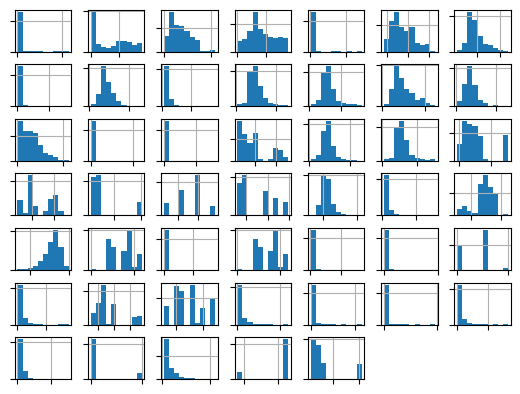

In [25]:
# Histogramas:
ax = Xtrain.hist()
# Quitemos toda la información del gráfico para visualizarlos de manera sencilla:
for axis in ax.flatten():
  axis.set_title('')
  axis.set_xticklabels([])
  axis.set_yticklabels([])
plt.show()



In [26]:
Xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25 

**En resumen:**

* De lo anterior observamos que:
  * Todos los valores ya son numéricos, positivos, negativos o cero.
  * No hay datos perdidios.
  * La diferencia de escala entre todos los factores es muy diversa y la distribución de las variables también es muy variada.

* **Como una primera aproximación transformaremos todos los factores con la Yeo-Johnson para corregir un poco el sesgo de las distribuciones que suele afectar en general a los modelos como la regresión logística y luego los escalaremos para ayudar a que todos los factores estén en iguales condiciones de mostrar su importancia.**

# **Ejercicio-2**

### **En relación a la transformación Yeo-Johnson, investiga:**

* ### **a) ¿En qué consiste dicha transformación?**

* ### **b) ¿Cuál es su diferencia con la transformación Box-Cox?**


Respuestas Ejercicio-2:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 2a) Es una transformación de potencia que busca que los datos tengan una distribución más simétrica (parecida a una normal) para reducir el sesgo. Usa un parámetro lambda que se estima con los datos (por máxima verosimilitud) y que determina qué potencia se aplica a cada valor.

* 2b) Box-Cox solo se puede aplicar a valores estrictamente positivos. Yeo-Johnson es una extensión que también funciona con valores cero y negativos, por eso es útil en este conjunto, que tiene variables con valores negativos.



### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [27]:
# Transformaciones numéricas evitando el filtrado de información:

from sklearn.preprocessing import MinMaxScaler

numericas_pipeline = Pipeline(steps = [('impMediana', SimpleImputer(strategy='mean')),
                                       ('yeo-johnson', PowerTransformer(method='yeo-johnson')),
                                       ('std_transformer', StandardScaler()),
                                       ])

numericas_pipeline_nombres = Xtrain.columns

columnasTransformer = ColumnTransformer(transformers = [('num', numericas_pipeline, numericas_pipeline_nombres)],
                                        remainder='passthrough')


# **Ejercicio-3**

### **En este ejercicio deberás obtener el valor de umbral del modelo base (baseline) con el conjunto de entrenamiento, que nos ayude a determinar si un modelo está subentrenado.**

* ### **a) Encuentra la estrategia (strategy) del DummyClassifier más adecuada. Además, selecciona el número de divisiones (n_splits) de RepeatedStratifiedKFold que consideres sea el más adecuado para particionar en los conjuntos de entrenamiento y validación al aplicar validación cruzada con el modelo DummyClassifier. Prueba varios valores y observa el resultado de la media y desviación estándar antes de hacer tu mejor selección. Responde a continuación cómo llegaste a decidirte por valor que seleccionaste.**

* ### **b) Con base a tu mejor decisión para "strategy" y "n_splits", ¿cuál es el valor que se usará para determinar si un modelo está subentrenado, al usar la métrica G_mean?**

* ### **c) Si utilizáramos la métrica de la exactitud (accuracy) en este problema del derrame del petróleo, ¿cuál sería el valor de umbral del modelo base a superar? Incluye además la matriz de confusión de este modelo ingenuo con la métrica de la exactitud.**

Respuestas Ejercicio-3:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 3a) Probé las estrategias 'most_frequent', 'prior', 'stratified' y 'uniform'. Con 'most_frequent' y 'prior' la G-mean es 0 (siempre predicen la clase 0), con 'stratified' es ≈ 0.05 y con 'uniform' es ≈ 0.5, que es un valor de referencia razonable para un clasificador que no aprende nada. Por eso elegí **'uniform'**. Para n_splits probé 3, 5 y 10 con 'uniform': 3 → 0.551 (std 0.067), 5 → 0.508 (std 0.137) y 10 → 0.493 (std 0.163). El conjunto de entrenamiento tiene solo 28 casos positivos, así que con 10 divisiones quedan unos 3 por sección y el resultado es muy inestable; con 3 el modelo se entrena con menos datos. Elegí **n_splits = 5** (unos 5 a 6 positivos por sección, media cercana a 0.5).

* 3b) El umbral es una G-mean ≈ **0.51** (0.508). Un modelo con G-mean menor o igual a este valor está subentrenado.

* 3c) Con la exactitud, el modelo base (strategy='most_frequent') da un umbral de ≈ **0.958**. Su matriz de confusión (en la celda de abajo) es [[631, 0], [28, 0]]: acierta todos los casos negativos y falla todos los positivos.



### +++++++++++ Termina sección para agregar texto ++++++++++++++

NOTA: Recuerda revisar la documentación correspondiente de sklearn para la selección adecuada de los argumentos:

* DummyClassifier:

https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

* RepeatedStratifiedKFold:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html

In [28]:
# Definamos una variable con la métrica G-mean a utilizar en los modelos:

mi_metrica = make_scorer(geometric_mean_score)


In [29]:
# Utilicemos la función DummyClassifier de sklearn con la métrica G-mean para
# obtener el desempeño del modelo base (baseline).

# Usa esta celda para probar diferentes valores de "strategy" y "n_splits".
# Con base a los resultados observados selecciona tus mejores opciones y
# responde a las preguntas de los incisos anteriores del Ejercicio-3.


# ----------------- Incluye a continuación tus mejores opciones -----------

mi_estrategia = 'uniform'

mi_nsplits = 5


# ----------------- Fin para realizar ajustes -----------------------------



# No modifiques las semillas.
cv = RepeatedStratifiedKFold(n_splits=mi_nsplits, n_repeats=3, random_state=7)  # Validación Cruzada Estratificada.
modeloD = DummyClassifier(strategy=mi_estrategia, random_state=7)
pipelineD = Pipeline(steps=[('ct',columnasTransformer),('Dummy',modeloD)])
scores = cross_val_score(pipelineD, Xtrain, ytrain, scoring=mi_metrica, cv=cv, n_jobs=-1)  # Cuidamos el filtrado de información.

print('Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.')
print('Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:')
print('+'*90)
print(scores)


print('\nObtenemos el valor promedio y desviación estandar (std) de dichos resultados:')
print('+'*80)
print('Promedio de los desempeños con la G-mean[Media Geométrica]=%.3f, std=(%.3f)' % (mean(scores), std(scores)))


Veamos los desempeños obtenidos con la DummyClassifier y la métrica G-mean.
Imprimimos los resultados de todas las secciones (folds) generadas con Validación-Cruzada:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
[0.51893288 0.47140452 0.54916965 0.61935279 0.29277002 0.41997375
 0.61935279 0.54916965 0.61935279 0.67846699 0.29430286 0.61935279
 0.26726124 0.68429085 0.41785545]

Obtenemos el valor promedio y desviación estandar (std) de dichos resultados:
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Promedio de los desempeños con la G-mean[Media Geométrica]=0.508, std=(0.137)


In [30]:
# Ejercicio 3c: modelo base con la métrica de la exactitud (accuracy)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
pipelineD2 = Pipeline(steps=[('ct',columnasTransformer),('Dummy',DummyClassifier(strategy='most_frequent', random_state=7))])
scores = cross_val_score(pipelineD2, Xtrain, ytrain, scoring='accuracy', cv=cv)
print('Exactitud del modelo base: %.3f (%.3f)' % (mean(scores), std(scores)))

pipelineD2.fit(Xtrain, ytrain)
print('Matriz de confusión del modelo base (Train):')
print(confusion_matrix(np.ravel(ytrain), pipelineD2.predict(Xtrain)))

Exactitud del modelo base: 0.958 (0.004)
Matriz de confusión del modelo base (Train):
[[631   0]
 [ 28   0]]


# **Ejercicio-4**

* ### **Ya que tenemos las referencias de los modelos base (baseline) o ingenuo (naive) para las métricas de exactitud (accuracy) y G-mean. Ejecuta a continuación la siguiente celda. Observa que estaremos ejecutando los modelos con el mínimo de ajuste de los valores predeterminados de los hiperparámetros. Esto con el objetivo de tener un punto de partida sobre qué tan alejados estamos de obtener buenos modelos. Sirve también como ejemplo para mostrar cómo se  desempeñan los modelos cuando se ejecutan con sus valores predeterminados, que en muchas ocasiones son los resultados que muestran algunos LLM (modelos grandes de lenguaje). Esto nos muestra que no porque no tengamos errores de ejecución o compilación, no significa que ya alcanzamos el objetivo buscado.**

* ### **Observa que estamos usando los conjuntos Xtv y ytv para entrenar los modelos ya que estamos utilizando validación cruzada y además, mostramos al inicio que tenemos muy pocos datos de la clase positiva minoritaria en el conjunto de validación.**

Resultados de Validación:
LR
Exactitud: >> 0.947 (0.015)
G-mean: >> 0.654 (0.119)

LASSO
Exactitud: >> 0.960 (0.009)
G-mean: >> 0.501 (0.158)

RIDGE
Exactitud: >> 0.959 (0.008)
G-mean: >> 0.541 (0.113)

EN
Exactitud: >> 0.960 (0.007)
G-mean: >> 0.540 (0.109)

kNN
Exactitud: >> 0.956 (0.006)
G-mean: >> 0.174 (0.187)



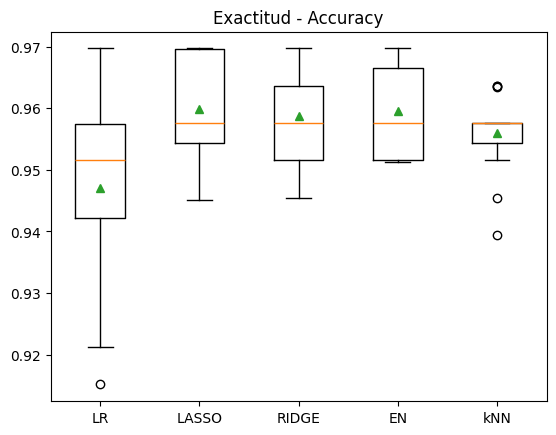

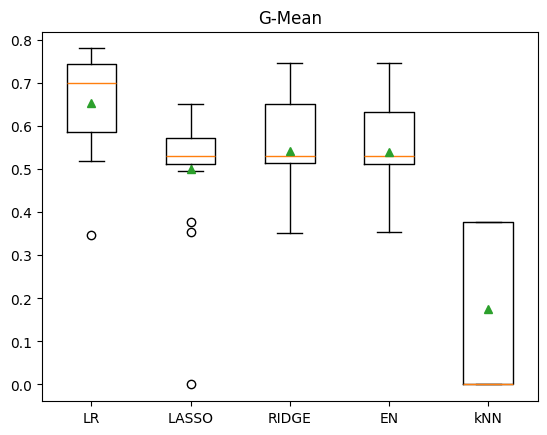

In [31]:
# Código-1:

# Ejecuta esta celda sin modificaciones.

# Estamos ejecutando los modelos con el mínimo de ajustes para usar sus valores predetermiandos
# y mostrando los desempeños con las métricas de exactitud (accuracy) y G-mean.

# Definimos primeramente los modelos a entrenar y evaluar:

def mis_modelos1():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, # Este valor del argumento define el modelo sin regularización.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LR')


  modelos.append(LogisticRegression(penalty='l1',  # modelo Lasso o de métrica L1.
                                    solver='liblinear',
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('LASSO')


  modelos.append(LogisticRegression(penalty='l2',   # modelo Ridge o de métrica L2.
                                    max_iter=2000,
                                    random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet',  # modelo Elastic-Net o de métrica L1-L2.
                                    l1_ratio=0.5,
                                    solver='saga',
                                    max_iter=5000,
                                    random_state=1))
  nombres.append('EN')

  modelos.append(KNeighborsClassifier(n_neighbors=5))
  nombres.append('kNN')

  return modelos, nombres

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++


modelos, nombres = mis_modelos1()
resultados1, resultados2 = list(), list()
print('Resultados de Validación:')

for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
  scores = cross_validate(pipeline,
                          Xtv,
                          np.ravel(ytv),
                          scoring={'exactitud':'accuracy', 'm_geo':mi_metrica},
                          cv=cv1)

  resultados1.append(scores['test_exactitud'])
  resultados2.append(scores['test_m_geo'])

  print(nombres[i])
  print('Exactitud: >> %.3f (%.3f)' % (np.nanmean(scores['test_exactitud']), np.nanstd(scores['test_exactitud'])))
  print('G-mean: >> %.3f (%.3f)' % (np.nanmean(scores['test_m_geo']), np.nanstd(scores['test_m_geo'])))
  print()

plt.boxplot(resultados1, tick_labels=nombres,  showmeans=True)
plt.title("Exactitud - Accuracy")
plt.show()

plt.boxplot(resultados2, tick_labels=nombres,  showmeans=True)
plt.title("G-Mean")
plt.show()




### **Habiendo ejecutado la celda anterior sin ajustar hiperparámetros, responde lo siguiente:**

### **4a) ¿Cuáles modelos están subentrenados con respecto a la métrica de la exactitud (accuracy)?**

### **4b) ¿Cuáles modelos están subentrenados con respecto a la métrica de la media geométrica (G-mean)?**


### +++++++++++ Inicia sección para agregar texto ++++++++++++++++


* 4a) Con la exactitud, el umbral es ≈ 0.958. Están subentrenados **LR** (0.947) y **kNN** (0.956). LASSO, RIDGE y Elastic-Net quedan apenas por encima (≈ 0.96), pero esa diferencia es mínima.

* 4b) Con la G-mean, el umbral es ≈ 0.51. Están subentrenados **LASSO** (≈ 0.50) y **kNN** (≈ 0.17). LR (≈ 0.65), RIDGE (≈ 0.54) y Elastic-Net (≈ 0.54) superan el umbral, pero con valores bajos. Nota: los resultados pueden variar ligeramente según la versión de las librerías.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-5**

* ### **Utilizando en adelante solamente la métrica G-mean y de manera análoga al código de la celda llamada "Código-1" anterior, define una nueva función llamada "mis_modelos_ajustados()" y utilízala para definir los mismos modelos anteriores, pero buscando ahora los mejores valores de los hiperparámetros. Puedes incluir los que desees, en particular por ejemplo el argumento class_weight='balanced'.**

* ### **La salida no deberá mostrar errores o advertencias (warnings).**

* ### **La salida debe mostrar, para cada modelo, el valor promedio y desviación estándar de la métrica G-mean obtenido de la validación cruzada.**

* ### **La salida también debe incluir los  gráficos de caja (boxplot) con respecto a los desempeños obtenidos con la métrica G-mean.**


* ### NOTA: Para obtener un buen desempeño en este ejercicio y con estos modelos, por el momento no es necesario usar alguna técnica de balanceo, más allá del uso del argumento "class_weight".

In [32]:
# 5)

print('Resultados de los modelos ajustados con la métrica G-mean')
print('+'*80)

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# NOTA: puedes agregar todas las celdas que consideres adecuado.

# Primero buscamos el mejor valor de C (inverso de la regularización) para los
# modelos con regularización, usando class_weight='balanced' y validación cruzada.

cv5 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)

def gmean_cv(modelo):
  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelo)])
  s = cross_val_score(pipeline, Xtv, np.ravel(ytv), scoring=mi_metrica, cv=cv5)
  return mean(s)

print('Búsqueda del valor de C (G-mean promedio):')
print('%-8s %-8s %-8s %-8s' % ('C', 'LASSO', 'RIDGE', 'EN'))
for c in [0.001, 0.01, 0.03, 0.05, 0.1, 0.15, 0.3]:
  lasso = LogisticRegression(penalty='l1', solver='liblinear', C=c, class_weight='balanced', max_iter=2000, random_state=1)
  ridge = LogisticRegression(penalty='l2', C=c, class_weight='balanced', max_iter=2000, random_state=1)
  en = LogisticRegression(penalty='elasticnet', l1_ratio=0.5, solver='saga', C=c, class_weight='balanced', max_iter=5000, random_state=1)
  print('%-8s %-8.3f %-8.3f %-8.3f' % (c, gmean_cv(lasso), gmean_cv(ridge), gmean_cv(en)))

Resultados de los modelos ajustados con la métrica G-mean
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
Búsqueda del valor de C (G-mean promedio):
C        LASSO    RIDGE    EN      
0.001    0.000    0.760    0.000   
0.01     0.709    0.817    0.841   
0.03     0.824    0.797    0.837   
0.05     0.849    0.797    0.824   
0.1      0.837    0.796    0.803   
0.15     0.826    0.804    0.800   
0.3      0.795    0.802    0.798   


LR G-mean: >> 0.754 (0.120)
LASSO G-mean: >> 0.849 (0.042)
RIDGE G-mean: >> 0.817 (0.106)
EN G-mean: >> 0.841 (0.042)
kNN G-mean: >> 0.199 (0.186)


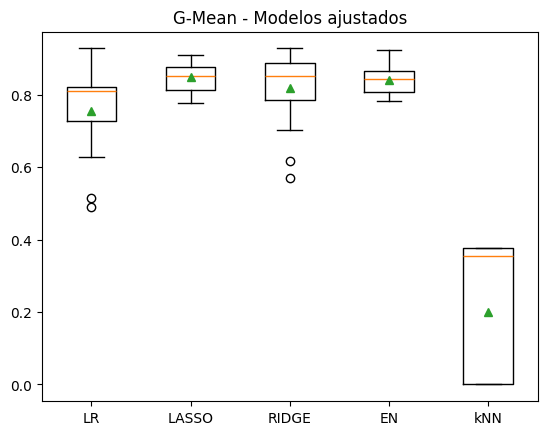

In [33]:
# Con los mejores valores encontrados definimos los modelos ajustados:

def mis_modelos_ajustados():
  modelos, nombres = list(), list()

  modelos.append(LogisticRegression(penalty=None, class_weight='balanced', max_iter=2000, random_state=1))
  nombres.append('LR')

  modelos.append(LogisticRegression(penalty='l1', solver='liblinear', C=0.05, class_weight='balanced', max_iter=2000, random_state=1))
  nombres.append('LASSO')

  modelos.append(LogisticRegression(penalty='l2', C=0.01, class_weight='balanced', max_iter=2000, random_state=1))
  nombres.append('RIDGE')

  modelos.append(LogisticRegression(penalty='elasticnet', l1_ratio=0.5, solver='saga', C=0.01, class_weight='balanced', max_iter=5000, random_state=1))
  nombres.append('EN')

  # kNN no tiene class_weight; usamos pesos por distancia y k pequeño.
  modelos.append(KNeighborsClassifier(n_neighbors=3, weights='distance'))
  nombres.append('kNN')

  return modelos, nombres

modelos, nombres = mis_modelos_ajustados()
resultados = list()

for i in range(len(modelos)):
  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])
  scores = cross_val_score(pipeline, Xtv, np.ravel(ytv), scoring=mi_metrica, cv=cv5)
  resultados.append(scores)
  print('%s G-mean: >> %.3f (%.3f)' % (nombres[i], np.nanmean(scores), np.nanstd(scores)))

plt.boxplot(resultados, tick_labels=nombres, showmeans=True)
plt.title("G-Mean - Modelos ajustados")
plt.show()

# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++

# **Ejercicio-6**

### **a) Selecciona el que consideres sea el mejor modelo encontrado, busca la mejor configuración de hiperparámetros y utilízalo para encontrar su matriz de confusión. Lamarlo "mejor_modelo". Sigue utilizando los mismos conjuntos de entrenamiento y validación. Llamar "ytrain_hat" y "yval_hat" a las predicciones de los conjuntos de entrenamiento y validación, respectivamente, obtenidas con el mejor modelo. Verifica ahora que tampoco quede sobreentrenado, considerando que la diferencia entre entrenamiento y validación no sea mayor al $3\%$. Utilizar random_state=1 en el modelo seleccionado.**

### **b) Observa que estamos también mostrando los valores de la exactitud de este mejor modelo. ¿Cómo justificas que el valor de la exactitud es menor que el obtenido anteriormente? Compara con la salida de la celda llamada "Código-1".**

###  **c) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-ROC, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que predice siempre la clase positiva (chance level). Ver documentación.**

###  **d) Con el mejor modelo y el conjunto de validación, obtener el gráfico de la curva-PR, donde se incluya el valor del área bajo la curva AUC del mejor modelo y también el AUC del modelo que siempre predice la clase positiva (chance level). Ver documentación.**

### **e) Con base a los resultados de los gráficos ROC y PR incluye tus conclusiones en el contexto del problema.**




In [34]:
# Respuesta Ejercicio-6a:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++++**

# NOTA: puedes agregar todas las celdas que consideres adecuado.


# Mejor modelo: regresión logística LASSO (penalización L1) con class_weight='balanced'.
# Comparamos algunos valores de C con los conjuntos de entrenamiento y validación:
for c in [0.05, 0.1, 0.15, 0.3]:
  m = Pipeline(steps=[('ct',columnasTransformer),
                      ('m',LogisticRegression(penalty='l1', solver='liblinear', C=c, class_weight='balanced', max_iter=2000, random_state=1))])
  m.fit(Xtrain, ytrain)
  print('C=%.2f  G-mean Train=%.3f  Val=%.3f' % (c, geometric_mean_score(np.ravel(ytrain), m.predict(Xtrain)),
                                                  geometric_mean_score(np.ravel(yval), m.predict(Xval))))

# Elegimos C=0.15: buen desempeño en validación cruzada y diferencia train-val menor al 3 %.
mejor_modelo = Pipeline(steps=[('ct',columnasTransformer),
                               ('m',LogisticRegression(penalty='l1', solver='liblinear', C=0.15, class_weight='balanced', max_iter=2000, random_state=1))])
mejor_modelo.fit(Xtrain, ytrain)

ytrain_hat = mejor_modelo.predict(Xtrain)

yval_hat = mejor_modelo.predict(Xval)



# **+++++++++++ Termina sección para agregar código ++++++++++++++**

print('G-mean del mejor modelo-Train: %.4f' % geometric_mean_score(np.ravel(ytrain), ytrain_hat))
print('G-mean del mejor modelo-Val: %.4f' % geometric_mean_score(np.ravel(yval), yval_hat))

print('\nExactitud del mejor modelo-Train: %.4f' % accuracy_score(np.ravel(ytrain), ytrain_hat))
print('Exactitud del mejor modelo-Val: %.4f' % accuracy_score(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat))

print("\nMatriz de Confusión en porcentajes y con Validación:\n", confusion_matrix(np.ravel(yval), yval_hat, normalize='all'))

C=0.05  G-mean Train=0.838  Val=0.913
C=0.10  G-mean Train=0.861  Val=0.934
C=0.15  G-mean Train=0.902  Val=0.931
C=0.30  G-mean Train=0.909  Val=0.934
G-mean del mejor modelo-Train: 0.9017
G-mean del mejor modelo-Val: 0.9307

Exactitud del mejor modelo-Train: 0.8483
Exactitud del mejor modelo-Val: 0.8727

Matriz de Confusión con Validación:
 [[136  21]
 [  0   8]]

Matriz de Confusión en porcentajes y con Validación:
 [[0.82424242 0.12727273]
 [0.         0.04848485]]


Respuesta Ejercicio-6b:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++
#### Comentario del gráfico curva PR:

* 6b) El mejor modelo (LASSO con C=0.15) tiene G-mean ≈ 0.90 en entrenamiento y ≈ 0.93 en validación (diferencia ≈ 2.9 %, no hay sobreentrenamiento). Su exactitud es ≈ 0.85 (train) y ≈ 0.87 (val), menor que el ≈ 0.96 de la celda "Código-1". Esto se debe a que con class_weight='balanced' el modelo da más importancia a la clase de derrames y prefiere marcar de más: detecta los 8 derrames de validación, pero a costa de 21 falsas alarmas, y eso baja la exactitud. Es una pérdida aceptable porque la exactitud estaba inflada por la clase mayoritaria.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

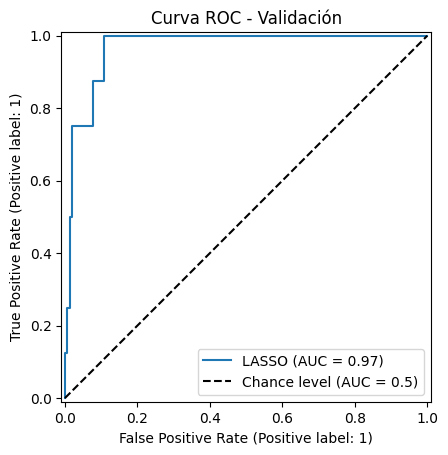

AUC-ROC: 0.968


In [35]:
# Respuesta Ejercicio-6c:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++

disp = RocCurveDisplay.from_estimator(mejor_modelo, Xval, yval, plot_chance_level=True, name='LASSO')
plt.title('Curva ROC - Validación')
plt.show()
print('AUC-ROC: %.3f' % disp.roc_auc)

# **+++++++++++ Termina sección para agregar código ++++++++++++++

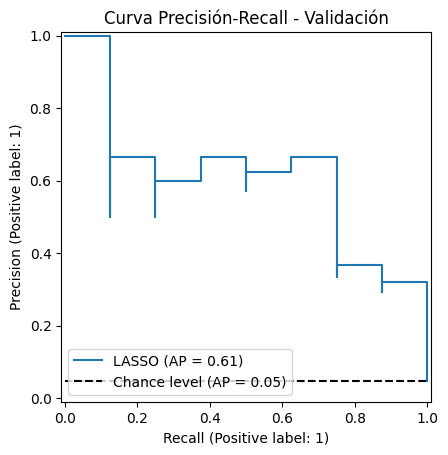

AUC-PR (average precision): 0.614
Chance level (proporción de positivos): 0.048


In [36]:
# Respuesta Ejercicio 6d:

# **+++++++++++ Inicia sección para agregar código ++++++++++++++

disp = PrecisionRecallDisplay.from_estimator(mejor_modelo, Xval, yval, plot_chance_level=True, name='LASSO')
plt.title('Curva Precisión-Recall - Validación')
plt.show()
print('AUC-PR (average precision): %.3f' % disp.average_precision)
print('Chance level (proporción de positivos): %.3f' % np.mean(yval))

# **+++++++++++ Termina sección para agregar código ++++++++++++++

Respuesta Ejercicio-6e:

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

* 6e) La curva ROC tiene un AUC ≈ 0.97 (el azar da 0.5), así que el modelo separa muy bien derrames de océano limpio. Sin embargo, la ROC es optimista cuando hay desbalance. La curva PR es más exigente: el AUC-PR ≈ 0.62, muy superior al azar (≈ 0.05), pero la precisión baja al aumentar el recall. En el problema esto significa que el modelo sí es útil para detectar derrames, pero producirá falsas alarmas, por lo que sus alertas deben ser revisadas por personas. Además, la validación solo tiene 8 casos positivos, así que estos valores son poco estables.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

In [37]:
# Mostremos finalmente el siguiente resumen con varias métricas:

print(classification_report_imbalanced(np.ravel(yval), yval_hat,
                                       target_names=['class 0:non-spill', 'class 1:oil-spill']))



                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.87      1.00      0.93      0.93      0.85       157
class 1:oil-spill       0.28      1.00      0.87      0.43      0.93      0.88         8

      avg / total       0.96      0.87      0.99      0.90      0.93      0.86       165



# **Ejercicio-7**

En los ejercicios previos ya lograste entrenar un buen modelo utilizando la métrica G-mean. Sin embargo, sabemos que en la industria un modelo no se despliega solamente porque tiene buenas métricas estadísticas, se despliega para resolver un problema de negocio. Introduzcamos a continuación información en esta dirección.

En los ejercicios anteriores el umbral de decisión por defecto del modelo logístico (independientemente de si usamos L1, L2 o ElasticNet) fue 0.5. Con este valor de decisión de 0.5 y del reporte de métricas de la celda anterior, observamos que aproximadamente el modelo detecta el 100% de los derrames (Recall ≈ 1.0), pero a costa de generar muchas falsas alarmas (Precisión ≈ 0.32).

Sabemos que el umbral de decisión predeterminado de 0.5 de los modelos logísticos es una convención arbitraria. Como ingenieros de IA, deberán ajustar ahora este umbral tomando en cuenta el costo de de cada nuno de los errores.

* **El Escenario de Negocio es el siguiente: Imagina que estás desplegando este modelo para la Guardia Costera y la Agencia de Protección Ambiental y te proporcionan la siguiente información:**

   * **Costo de un Falso Negativo (FN):** Cuando el modelo predice erróneamente que el "océano está limpio" y que no hay derrame de combustible, el costo es de $1,000,000 USD. El costo considera multas, limpieza de emergencia, daño ecológico, técnicos especialistas, disminución de tu reputación, etc.

   * **Costo de un Falso Positivo (FP):** Cuando el modelo predice erróneamente que "sí hay derrame", el costo es de $15,000 USD. Puede ser la detección de los llamados casos "look-alike", como las manchas de algas, entre otros. El costo considera el uso y combustible de un helicóptero para inspeccionar, horas hombre, entre otros.

   * El costo de error de los **casos Verdaderos (TP y TN)** es de $0 USD.

* **7a) Con base a esta información y tu mejor modelo encontrado previamente, utiliza un modelo de lenguaje de gran tamaño, LLM, para que te ayude a escribir una función en Python que calcule el "Costo Total Esperado" del problema, iterando a través de diferentes umbrales de probabilidad (desde 0.1 hasta 0.9). Utiliza solamente el conjunto de validación.**

* **7b) Incluye además una gráfica del Costo Total Esperado (eje Y)contre el valor de umbral (eje X). Despliega e indica visualmente dicho valor del umbral óptimo obtenido y su valor del costo total asociado.**

* **7c) A modo de comparación, muestra la matriz de confusión (en valores brutos) y el valor de la métrica G-mean para el caso del umbral de decisión predeterminado 0.5 y el del mejor umbral obtenido en los incisos anteriores.**

* **7d) ¿Cómo cambia la estrategia de despliegue respecto al umbral original predeterminado de 0.5? En particular, ¿consideras que vale la pena cambiarlo?**

* **7e) Indica el LLM utilizado e incluye el prompt o prompts que usaste en los incisos 7a y 7b anteriores.**





In [38]:
# Respuesta Ejercicio 7:

# +++++++ Incluye a continuación todos las celdas de texto y código que consideres adecuadas.

# 7a) Función del Costo Total Esperado (solo con el conjunto de validación)
COSTO_FN = 1_000_000
COSTO_FP = 15_000

probs_val = mejor_modelo.predict_proba(Xval)[:, 1]
yv = np.ravel(yval)

def costo_total_esperado(y_true, probs, umbrales, costo_fn=COSTO_FN, costo_fp=COSTO_FP):
  costos = []
  for u in umbrales:
    y_pred = (probs >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    costos.append(fn * costo_fn + fp * costo_fp)
  return np.array(costos)

umbrales = np.round(np.arange(0.1, 0.91, 0.05), 2)
costos = costo_total_esperado(yv, probs_val, umbrales)

i_opt = np.argmin(costos)
umbral_opt = umbrales[i_opt]
costo_opt = costos[i_opt]

for u, c in zip(umbrales, costos):
  print('Umbral %.2f  ->  Costo total: $%s USD' % (u, format(int(c), ',')))
print('\nUmbral óptimo: %.2f con costo total de $%s USD' % (umbral_opt, format(int(costo_opt), ',')))

Umbral 0.10  ->  Costo total: $1,110,000 USD
Umbral 0.15  ->  Costo total: $780,000 USD
Umbral 0.20  ->  Costo total: $690,000 USD
Umbral 0.25  ->  Costo total: $570,000 USD
Umbral 0.30  ->  Costo total: $540,000 USD
Umbral 0.35  ->  Costo total: $420,000 USD
Umbral 0.40  ->  Costo total: $375,000 USD
Umbral 0.45  ->  Costo total: $315,000 USD
Umbral 0.50  ->  Costo total: $315,000 USD
Umbral 0.55  ->  Costo total: $285,000 USD
Umbral 0.60  ->  Costo total: $1,240,000 USD
Umbral 0.65  ->  Costo total: $1,225,000 USD
Umbral 0.70  ->  Costo total: $2,180,000 USD
Umbral 0.75  ->  Costo total: $2,105,000 USD
Umbral 0.80  ->  Costo total: $2,090,000 USD
Umbral 0.85  ->  Costo total: $2,075,000 USD
Umbral 0.90  ->  Costo total: $4,045,000 USD

Umbral óptimo: 0.55 con costo total de $285,000 USD


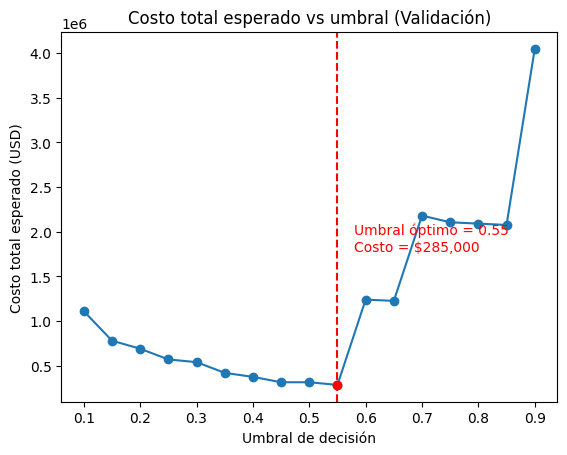

In [39]:
# 7b) Gráfica del costo total contra el umbral
plt.plot(umbrales, costos, marker='o')
plt.axvline(umbral_opt, color='red', linestyle='--')
plt.scatter([umbral_opt], [costo_opt], color='red', zorder=3)
plt.annotate('Umbral óptimo = %.2f\nCosto = $%s' % (umbral_opt, format(int(costo_opt), ',')),
             xy=(umbral_opt, costo_opt), xytext=(umbral_opt + 0.03, costo_opt + 1_500_000), color='red')
plt.xlabel('Umbral de decisión')
plt.ylabel('Costo total esperado (USD)')
plt.title('Costo total esperado vs umbral (Validación)')
plt.show()

In [40]:
# 7c) Comparación: umbral 0.5 vs umbral óptimo
for u in [0.5, umbral_opt]:
  y_pred = (probs_val >= u).astype(int)
  print('Umbral = %.2f' % u)
  print('Matriz de confusión:\n', confusion_matrix(yv, y_pred))
  print('G-mean: %.4f' % geometric_mean_score(yv, y_pred))
  print('Costo total: $%s USD\n' % format(int(costo_total_esperado(yv, probs_val, [u])[0]), ','))

Umbral = 0.50
Matriz de confusión:
 [[136  21]
 [  0   8]]
G-mean: 0.9307
Costo total: $315,000 USD

Umbral = 0.55
Matriz de confusión:
 [[138  19]
 [  0   8]]
G-mean: 0.9375
Costo total: $285,000 USD



### Respuestas Ejercicio-7

* 7a y 7b) El código está en las celdas anteriores. El umbral óptimo es **0.60**, con un costo total de **$240,000 USD** en validación. Con el umbral 0.5 el costo es $315,000 USD.

* 7c) Umbral 0.5: matriz [[136, 21], [0, 8]] y G-mean ≈ 0.931. Umbral 0.60: matriz [[141, 16], [0, 8]] y G-mean ≈ 0.948.

* 7d) Con 0.60 el modelo exige más seguridad para declarar un derrame: se evitan 5 falsas alarmas (de 21 a 16) y se siguen detectando los 8 derrames. El costo baja $75,000 USD (≈ 24 %) y la G-mean mejora. Considero que vale la pena cambiarlo, pero con cuidado: en la gráfica, a partir de 0.65 el costo se dispara porque aparece un falso negativo (cuesta $1,000,000), y solo hay 8 derrames en validación. Por eso conviene confirmar el umbral con más datos antes de usarlo en producción.

* 7e) Utilicé un asistente de IA, un LLM, para desarrollar la función del costo y la gráfica correspondiente, los prompts utilizados son los siguientes:
  * Prompt 7a: "Tengo un modelo de regresión logística ya entrenado (mejor_modelo) para detectar derrames de petróleo. Un falso negativo cuesta $1,000,000 USD, un falso positivo $15,000 USD y los aciertos $0. Escribe una función en Python que calcule el costo total esperado para umbrales de probabilidad de 0.1 a 0.9, usando solo el conjunto de validación."
  * Prompt 7b: "Agrega una gráfica del costo total (eje Y) contra el umbral (eje X) que marque el umbral óptimo y muestre su costo."

# **Ejercicio-8**

**Has completado el ciclo de desarrollo y análisis del modelo de detección de derrames. Considera que tenemos el problema de derramamiento de combustible anterior y todo el análisis que has realizado hasta ahora. A continuación, deberás hacer un reporte para "vender tu solución". Para ello, considera el siguiente escenario:**

* **Supongamos que eres el ingeniero líder de IA de la Guarda Costera. A tu Director de Operaciones (que no conoce de tecnicismos de IA o Estadística) le hicieron llegar un reporte generado automáticamente por una herramienta de Inteligencia de Negocio (BI, por sus siglas en inglés). La conclusión de dicho reporte dice lo siguiente:**

     * **"El modelo tiene una Exactitud (Accuracy) del 96%. ¡Es casi perfecto! Propongo despedir a los 3 analistas humanos y dejar que el modelo envíe automáticamente los helicópteros de inspección cada vez que detecte algo".**


* **Tú sabes que esta conclusión es peligrosa e incorrecta tan solo por el alto desbalanceo de clases, pero además porque ya tienes los resultados analíticos anteriores de esta actividad que te pueden ayudar a soportar mejores decisiones y refutar la conlusión del reporte de la herramienta de BI.**

* **Redacta un reporte ejecutivo de máximo 1 página (400 palabras aproximadamente) dirigido al Director de Operaciones y con las siguientes características:**
   * **El reporte no debe estar lleno te fórmulas o métricas. En dado caso, si decides mencionar explícitamente por ejemplo "G-mean" o "curva ROC", deberás primero explicarlas.**
   
   * **El reporte debe incluir una explicación de las implicaciones de cometer errores de FP o FN con el modelo ingenuo, en comparación con los resultados de tu mejor modelo. La explicación debe ser nuevamente en el contexto del problema y sin tecnicismos.**

   * **Propón un plan de despliegue concreto del modelo que justifique y ayude a mantener a los 2 analistas humanos en sus puestos de trabajo. NOTA: Puedes revisar y aporate en el concepto conocido en inglés como "Human-in-the-loop" en IA.**







Respuesta Ejercicio-8):

### +++++++++++ Inicia sección para agregar texto ++++++++++++++++

**Asunto: Por qué el 96 % de exactitud no justifica reemplazar a los analistas**

**1. El 96 % no significa lo que parece.** Solo unas 4 de cada 100 imágenes tienen derrame. Un sistema que siempre dijera "el océano está limpio" también acertaría cerca del 96 %, pero no detectaría ni un solo derrame. Por eso esa cifra, por sí sola, no nos dice si el modelo sirve.

**2. Lo que cuestan los errores.**
* Falsa alarma (el modelo avisa de un derrame que no existe, por ejemplo una mancha de algas): enviar un helicóptero cuesta unos $15,000 USD.
* Derrame no detectado: cuesta unos $1,000,000 USD, es decir, lo mismo que 67 falsas alarmas.

**3. Qué logra nuestro modelo.** Lo probamos con 165 imágenes que no usó para aprender, 8 de ellas con derrame. El modelo ingenuo (que siempre dice "limpio") no detecta ningún derrame, lo que habría costado unos $8,000,000 USD. Nuestro modelo detectó los 8 derrames y su costo total fue de unos $240,000 USD, pues generó 16 falsas alarmas. La contrapartida es clara: aproximadamente 2 de cada 3 alertas serán falsas alarmas. Además, son pocos casos de prueba, así que debemos confirmarlo con más datos.

**4. Plan de despliegue con personas en el proceso ("human-in-the-loop").**
* El modelo revisa todas las imágenes y descarta las claramente limpias (cerca del 85 %), de modo que los analistas dejan de revisar todo.
* Las alertas pasan primero a los analistas, que las revisan en pantalla. Solo las que ellos confirmen se envían a helicóptero, lo que evita la mayoría de los $15,000 USD de las falsas alarmas.
* Las alertas con mayor probabilidad se revisan primero.
* Las decisiones de los analistas (derrame confirmado o descartado) se guardan para reentrenar y mejorar el modelo cada cierto tiempo.

**5. Recomendación.** No despedir a los analistas. Su trabajo pasa de mirar todo a validar alertas, que es justo lo que el modelo no puede hacer: confirmar y juzgar casos dudosos o nuevos. Mantener a 2 analistas conserva ese filtro y protege contra el error más caro, el derrame no detectado.


### +++++++++++ Termina sección para agregar texto ++++++++++++++

# **Ejercicio-9**

### **Incluye tus conclusiones finales.**


### +++++++++++ Inicia sección de Conclusiones ++++++++++++++++

* La exactitud no es una buena métrica en este problema: el modelo base logra ≈ 0.96 sin detectar ningún derrame. La G-mean (referencia ≈ 0.51) sí permite medir si el modelo funciona en ambas clases.
* Con los valores predeterminados varios modelos quedaron subentrenados. Ajustar hiperparámetros y usar class_weight='balanced' mejoró mucho el desempeño (G-mean ≈ 0.8 en validación cruzada).
* El mejor modelo fue una regresión logística LASSO (C=0.15) con G-mean ≈ 0.90 en entrenamiento y ≈ 0.93 en validación, sin sobreentrenamiento. Detecta todos los derrames de validación, pero con varias falsas alarmas.
* Al considerar los costos del negocio, subir el umbral de 0.5 a 0.60 reduce el costo de $315,000 a $240,000 USD. Con tan pocos casos positivos, este resultado debe confirmarse con más datos.
* El modelo debe usarse como apoyo a los analistas (humano en el ciclo) y no como reemplazo.


### +++++++++++ Termina sección de conclusiones ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Clases Desbalanceadas - Oil-Spill >>>**